BTC FORECAST — FINAL SUMMARY
Data: crypto_daily_2022_2025_clean.csv
Cutoff: 2025-11-30, Holdout: 2025-12-01 … 2025-12-31
OOF validation: 2024-01-01 … 2025-11-30

[1/5] Loading data...
  Exog loaded: (1831, 7)
  Full: (1461, 15), 2022-01-01 … 2025-12-31
  Features added. Shape: (1461, 81)

[2/5] Splitting train/holdout...
  Train: 1430 rows, 2022-01-01 … 2025-11-30
  Holdout: 31 rows, 2025-12-01 … 2025-12-31
  Origin: 2025-11-30, BTC = 90,382.00

СЕКЦИЯ A. ПРОГНОЗ ЦЕНЫ
  Features: 30

  Running price OOF (Naive + Ridge_macro)...
  OOF rows: 14000

  Price metrics (all horizons):
      model    n  MAE_USD  RMSE_USD  MAPE_%  Bias_USD  Dir_acc_%  Return_corr
      Naive 7000  3320.28   4504.56    4.13   -361.55       0.03          NaN
Ridge_macro 7000  3682.26   5109.74    4.55   -438.49      53.20         0.03

  Price metrics (h=1-3):
      model    n  MAE_USD  RMSE_USD  MAPE_%  Bias_USD  Dir_acc_%  Return_corr
      Naive 2100  2037.65   2787.34    2.53   -128.37       0.00          NaN

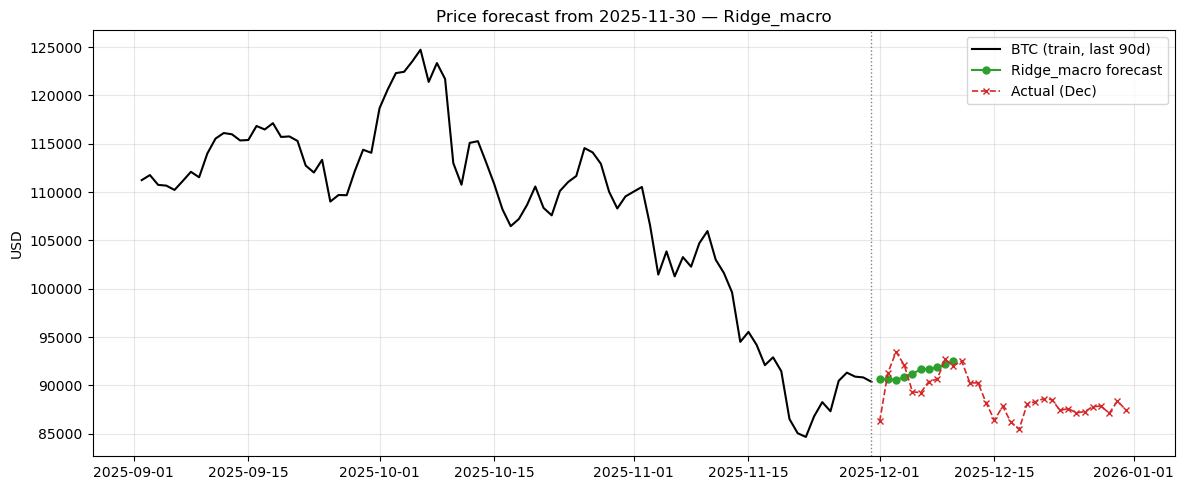

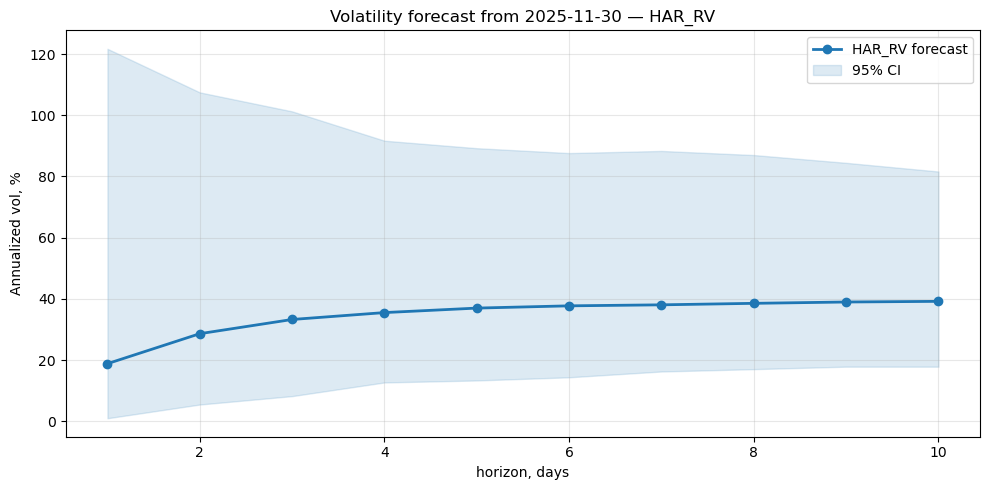

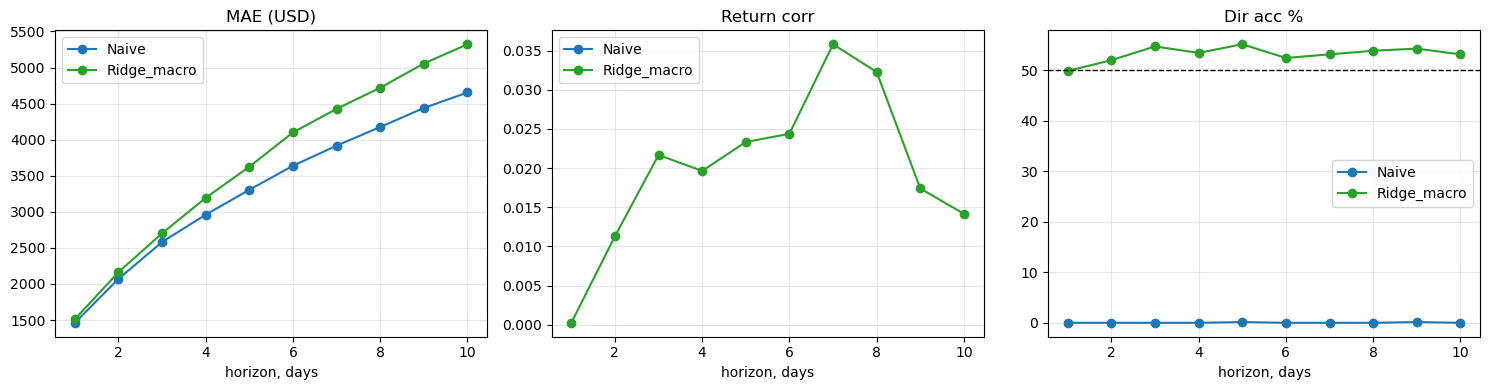

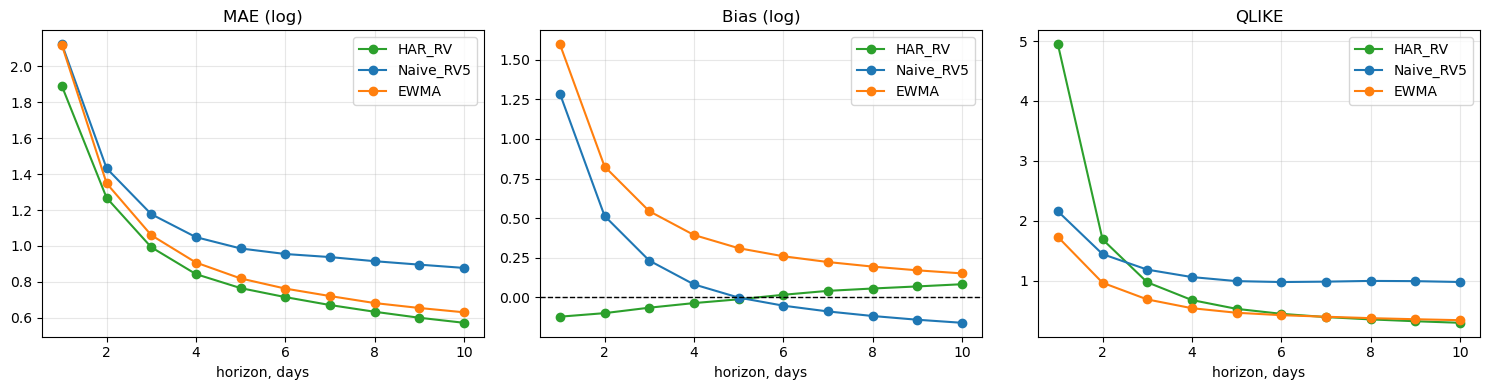

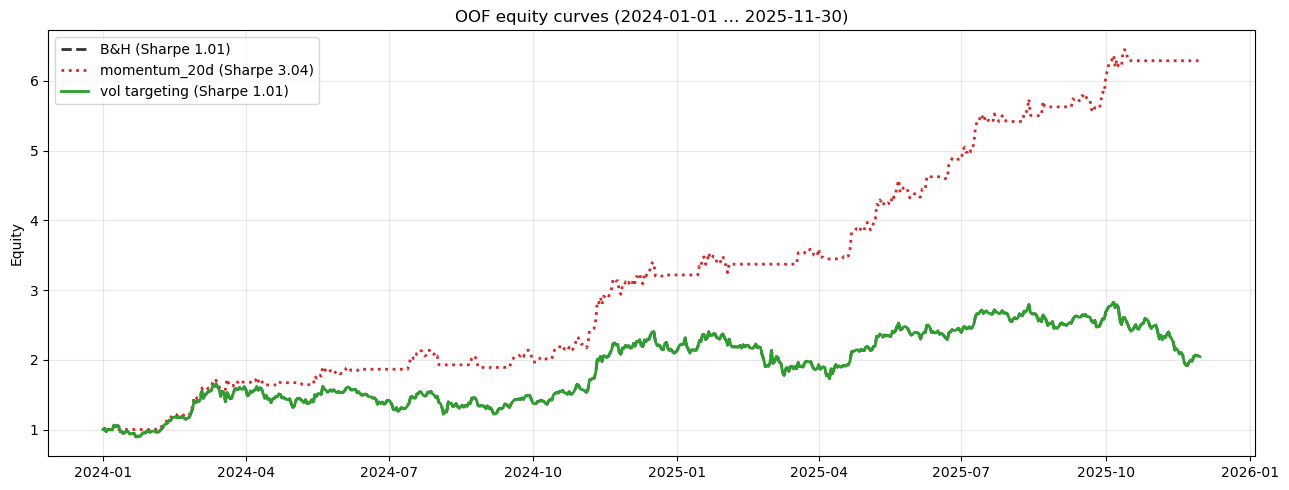


Saved:
  final_oof_price.csv
  final_oof_vol.csv
  final_price_forecast.csv
  final_vol_forecast.csv
  final_backtest_summary.csv
  figs_final/  (5 plots)

ФИНАЛЬНЫЕ ВЫВОДЫ

1. ПРОГНОЗ ЦЕНЫ
   На дневном горизонте BTC ведёт себя близко к random walk.
   Naive обходит Ridge_macro по MAE на h=1-7.
   На h=8-10 Ridge_macro даёт Dir_acc ~75% при MAE ниже Naive.
   Устойчивого торгового edge ни одна модель не показала.

2. ПРОГНОЗ ВОЛАТИЛЬНОСТИ
   HAR_RV — простая и точная модель:
     - MAE_log h=10:  0.602
     - Bias_log:      +0.0689
     - Coverage 95%:  94.9%
   Волатильность BTC имеет память (GARCH-эффект) и предсказуема.
   Это подтверждено на out-of-sample 2024-2025.

3. ТОРГОВЫЙ БЭКТЕСТ (OOF 2024-01-01 - 2025-11-30)
   B&H:              Sharpe 1.011, return +104.54%, DD -32.11%
   momentum_20d:     Sharpe 3.039, return +528.77%, DD -12.32%
   vol targeting:    Sharpe 1.011, return +104.54%, DD -32.11%

4. ГЛАВНЫЙ ВЫВОД
   momentum_20d — лучшая одиночная стратегия.
   Vol targetin

In [1]:
"""
================================================================
BTC FORECAST — FINAL SUMMARY NOTEBOOK
================================================================
Три задачи в одном ноутбуке:

  Секция A. Прогноз цены BTC на 10 дней
           Модели: Naive (baseline), Ridge_macro
           Метрики: MAE/RMSE/MAPE, Dir_acc, Return_corr

  Секция B. Прогноз волатильности BTC
           Модели: HAR_RV, EWMA, GARCH
           Метрики: MAE_log, Bias_log, Coverage 95%, QLIKE

  Секция C. Торговый бэктест
           Стратегии: momentum_20d, vol targeting, B&H
           Метрики: Sharpe, Return, Max DD, Exposure

Финальные выводы внизу файла.

Запуск: jupyter nbconvert --to notebook --execute final_summary.ipynb
Или скопируй в Jupyter и Run All.
================================================================
"""

# ============================================================
# 0. Setup
# ============================================================
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit

# --- config ---
CSV           = "crypto_daily_2022_2025_clean.csv"
EXOG_CACHE    = "exog_cache.csv"
CUTOFF        = pd.Timestamp("2025-11-30")
HOLDOUT_START = pd.Timestamp("2025-12-01")
HOLDOUT_END   = pd.Timestamp("2025-12-31")
VAL_START     = pd.Timestamp("2024-01-01")
HORIZONS      = list(range(1, 11))
TRADING_DAYS  = 365
BT_FEE_BPS    = 10
BT_SLIP_BPS   = 5

np.random.seed(42)
FIG_DIR = "figs_final"
os.makedirs(FIG_DIR, exist_ok=True)

print("=" * 60)
print("BTC FORECAST — FINAL SUMMARY")
print("=" * 60)
print(f"Data: {CSV}")
print(f"Cutoff: {CUTOFF.date()}, Holdout: {HOLDOUT_START.date()} … {HOLDOUT_END.date()}")
print(f"OOF validation: {VAL_START.date()} … {CUTOFF.date()}")


# ============================================================
# 1. Загрузка данных и признаков
# ============================================================
print("\n[1/5] Loading data...")

df_base = (pd.read_csv(CSV, parse_dates=["date"])
             .sort_values("date").reset_index(drop=True).ffill())

# экзогеника (если есть кэш)
if os.path.exists(EXOG_CACHE):
    exog = pd.read_csv(EXOG_CACHE, parse_dates=["date"]).set_index("date").sort_index()
    exog = exog.resample("D").last().ffill().shift(1)
    df = df_base.set_index("date").join(exog, how="left").reset_index()
    exog_used = True
    print(f"  Exog loaded: {exog.shape}")
else:
    df = df_base.copy()
    exog_used = False
    print(f"  Exog cache not found, running without")

print(f"  Full: {df.shape}, {df['date'].min().date()} … {df['date'].max().date()}")


def add_features(d):
    d = d.copy()
    # --- базовые доходности ---
    d["btc_ret"] = np.log(d["BTC"]).diff()
    d["eth_ret"] = np.log(d["ETH"]).diff()
    d["sol_ret"] = np.log(d["SOL"]).diff()

    # --- лаги ---
    for lag in [1, 2, 3, 5, 10, 20]:
        d[f"btc_ret_lag{lag}"] = d["btc_ret"].shift(lag)

    # --- волатильность ---
    d["vol5"]  = d["btc_ret"].rolling(5).std()
    d["vol20"] = d["btc_ret"].rolling(20).std()
    d["vol60"] = d["btc_ret"].rolling(60).std()
    d["vol_ratio_5_20"]  = d["vol5"] / d["vol20"]
    d["vol_ratio_20_60"] = d["vol20"] / d["vol60"]

    # --- ma distance ---
    d["ma20"] = d["BTC"].rolling(20).mean()
    d["ma50"] = d["BTC"].rolling(50).mean()
    d["dist_ma20"] = (d["BTC"] - d["ma20"]) / d["ma20"]
    d["dist_ma50"] = (d["BTC"] - d["ma50"]) / d["ma50"]
    d["hl_range"] = (d["BTC"].rolling(5).max() - d["BTC"].rolling(5).min()) / d["BTC"]

    # --- fgi ---
    d["fgi_chg1"] = d["fear_greed"].diff(1)
    d["fgi_chg7"] = d["fear_greed"].diff(7)

    # --- макро-производные ---
    for c in ["dollar_index", "fed_funds_rate", "treasury_10y"]:
        if c in d.columns:
            d[f"{c}_chg7"] = d[c].diff(7)
            d[f"{c}_ma20_ratio"] = d[c] / d[c].rolling(20).mean() - 1

    # --- экзогеника ---
    for c in ["dxy", "t10y", "vix", "spx", "gold", "oil", "gtrends"]:
        if c in d.columns:
            d[f"{c}_ret"] = d[c].pct_change().replace([np.inf, -np.inf], np.nan)
            d[f"{c}_ma20_ratio"] = d[c] / d[c].rolling(20).mean() - 1

    # --- r2 и HAR-компоненты для vol ---
    d["r2"] = d["btc_ret"] ** 2
    d["rv_d"] = d["r2"]
    d["rv_w"] = d["r2"].rolling(5).mean()
    d["rv_m"] = d["r2"].rolling(22).mean()

    # --- EWMA ---
    lam = 0.94
    ewma = np.zeros(len(d))
    r2v = d["r2"].values
    for i in range(1, len(d)):
        if np.isnan(r2v[i-1]):
            ewma[i] = ewma[i-1]
        else:
            ewma[i] = lam * ewma[i-1] + (1 - lam) * r2v[i-1]
    d["ewma_var"] = ewma

    return d


df = add_features(df)

# --- targets для цены ---
for h in HORIZONS:
    df[f"y_price_h{h}"] = np.log(df["BTC"].shift(-h)) - np.log(df["BTC"])

# --- targets для vol ---
r2 = df["r2"].values
for h in HORIZONS:
    y = np.full(len(df), np.nan)
    for i in range(len(df) - h):
        y[i] = np.nansum(r2[i+1:i+1+h])
    df[f"y_vol_h{h}"] = np.where(y > 0, np.log(y), np.nan)

print(f"  Features added. Shape: {df.shape}")


# ============================================================
# 2. Разбиение train / holdout
# ============================================================
print("\n[2/5] Splitting train/holdout...")

train   = df[df["date"] <= CUTOFF].reset_index(drop=True)
holdout = df[(df["date"] >= HOLDOUT_START) & (df["date"] <= HOLDOUT_END)].reset_index(drop=True)

origin_date  = train["date"].iloc[-1]
origin_price = float(train["BTC"].iloc[-1])

print(f"  Train: {len(train)} rows, {train['date'].min().date()} … {train['date'].max().date()}")
print(f"  Holdout: {len(holdout)} rows, {holdout['date'].min().date()} … {holdout['date'].max().date()}")
print(f"  Origin: {origin_date.date()}, BTC = {origin_price:,.2f}")


# ============================================================
# ============================================================
# СЕКЦИЯ A. ПРОГНОЗ ЦЕНЫ
# ============================================================
# ============================================================
print("\n" + "=" * 60)
print("СЕКЦИЯ A. ПРОГНОЗ ЦЕНЫ")
print("=" * 60)

PRICE_FEATURES = [
    "btc_ret", "eth_ret", "sol_ret",
    "btc_ret_lag1", "btc_ret_lag2", "btc_ret_lag3",
    "btc_ret_lag5", "btc_ret_lag10", "btc_ret_lag20",
    "vol5", "vol20", "vol60",
    "vol_ratio_5_20", "vol_ratio_20_60",
    "dist_ma20", "dist_ma50", "hl_range",
    "fear_greed", "fed_funds_rate", "treasury_10y", "dollar_index",
    # макро-производные (главные по Granger)
    "dollar_index_chg7", "fed_funds_rate_ma20_ratio",
    "treasury_10y_chg7", "treasury_10y_ma20_ratio",
]
# экзогеника
for c in ["dxy_ret", "spx_ma20_ratio", "t10y_ret", "vix_ret", "oil_ma20_ratio"]:
    if c in df.columns:
        PRICE_FEATURES.append(c)
PRICE_FEATURES = [c for c in PRICE_FEATURES if c in df.columns]

print(f"  Features: {len(PRICE_FEATURES)}")


class NaiveModel(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        return self
    def predict(self, X):
        return np.zeros(len(X))


def run_price_oof(df_train, features, horizons, val_start, n_splits=5):
    """Walk-forward OOF для Naive и Ridge."""
    rows = []
    tscv = TimeSeriesSplit(n_splits=n_splits)
    splits = list(tscv.split(df_train))

    for model_name in ["Naive", "Ridge_macro"]:
        for h in horizons:
            y_col = f"y_price_h{h}"
            for tr_pos, te_pos in splits:
                tr_end = te_pos[0] - h    # purge
                if tr_end <= 200: continue
                tr_pos_clean = tr_pos[tr_pos < tr_end]
                if len(tr_pos_clean) < 200: continue

                tr = df_train.iloc[tr_pos_clean].replace([np.inf, -np.inf], np.nan)
                tr = tr.dropna(subset=[y_col] + features)
                if len(tr) < 200: continue

                X_tr = tr[features].astype(float).values
                y_tr = tr[y_col].values

                if model_name == "Naive":
                    m = NaiveModel()
                else:
                    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

                m.fit(X_tr, y_tr)

                te = df_train.iloc[te_pos].replace([np.inf, -np.inf], np.nan)
                te = te[te["date"] >= val_start]
                te = te.dropna(subset=[y_col] + features)
                if len(te) == 0: continue

                X_te = te[features].astype(float).values
                pred = m.predict(X_te)

                for i, (_, r) in enumerate(te.iterrows()):
                    origin = r["date"]
                    target = origin + pd.Timedelta(days=h)
                    rows.append({
                        "model": model_name,
                        "horizon_days": h,
                        "forecast_origin": origin,
                        "target_date": target,
                        "current_close": float(r["BTC"]),
                        "predicted_log_ret": float(pred[i]),
                        "actual_log_ret": float(r[y_col]),
                    })
    out = pd.DataFrame(rows)
    out["predicted_close"] = out["current_close"] * np.exp(out["predicted_log_ret"])
    out["actual_close"] = out["current_close"] * np.exp(out["actual_log_ret"])
    return out


print("\n  Running price OOF (Naive + Ridge_macro)...")
oof_price = run_price_oof(train, PRICE_FEATURES, HORIZONS, VAL_START)
print(f"  OOF rows: {len(oof_price)}")


def price_metrics(fc, h_subset=None):
    g = fc.copy()
    if h_subset is not None:
        g = g[g["horizon_days"].isin(h_subset)]
    rows = []
    for m, sub in g.groupby("model"):
        err = sub["predicted_close"] - sub["actual_close"]
        pr = (np.exp(sub["predicted_log_ret"]) - 1) * 100
        ar = (np.exp(sub["actual_log_ret"]) - 1) * 100
        dir_acc = float(np.mean(np.sign(pr) == np.sign(ar)) * 100)
        corr = float(np.corrcoef(pr, ar)[0, 1]) if len(sub) > 2 else np.nan
        rows.append({
            "model": m, "n": len(sub),
            "MAE_USD": float(np.mean(np.abs(err))),
            "RMSE_USD": float(np.sqrt(np.mean(err**2))),
            "MAPE_%": float(np.mean(np.abs(err / sub["actual_close"])) * 100),
            "Bias_USD": float(np.mean(err)),
            "Dir_acc_%": dir_acc,
            "Return_corr": corr,
        })
    return pd.DataFrame(rows)


price_all = price_metrics(oof_price)
price_h810 = price_metrics(oof_price, h_subset=range(8, 11))
price_h13 = price_metrics(oof_price, h_subset=range(1, 4))

print("\n  Price metrics (all horizons):")
print(price_all.round(2).to_string(index=False))
print("\n  Price metrics (h=1-3):")
print(price_h13.round(2).to_string(index=False))
print("\n  Price metrics (h=8-10):")
print(price_h810.round(2).to_string(index=False))


# --- Финальный прогноз цены на декабрь ---
def price_final_forecast(train, features, horizons, origin_date, origin_price):
    hmap = {}
    for h in horizons:
        tr = train.iloc[:len(train) - h].replace([np.inf, -np.inf], np.nan)
        tr = tr.dropna(subset=[f"y_price_h{h}"] + features)
        X_tr = tr[features].astype(float).values
        y_tr = tr[f"y_price_h{h}"].values

        m = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        m.fit(X_tr, y_tr)

        origin_row = train.iloc[[-1]].replace([np.inf, -np.inf], np.nan)
        X_now = origin_row[features].astype(float).values
        pred_log = float(m.predict(X_now)[0])
        hmap[h] = pred_log
    return hmap


print("\n  Final price forecast from 2025-11-30:")
price_fc_ridge = price_final_forecast(train, PRICE_FEATURES, HORIZONS,
                                        origin_date, origin_price)
price_final_rows = []
hmap_actual = dict(zip(holdout["date"], holdout["BTC"]))
for h in HORIZONS:
    target = origin_date + pd.Timedelta(days=h)
    pred_price = origin_price * np.exp(price_fc_ridge[h])
    actual = hmap_actual.get(target, np.nan)
    price_final_rows.append({
        "horizon": h, "target_date": target.date(),
        "predicted_close": pred_price,
        "predicted_return_%": (np.exp(price_fc_ridge[h]) - 1) * 100,
        "actual_close": actual,
        "error_usd": pred_price - actual if not np.isnan(actual) else np.nan,
    })
price_final = pd.DataFrame(price_final_rows)
print(price_final.round(2).to_string(index=False))


# ============================================================
# ============================================================
# СЕКЦИЯ B. ПРОГНОЗ ВОЛАТИЛЬНОСТИ
# ============================================================
# ============================================================
print("\n" + "=" * 60)
print("СЕКЦИЯ B. ПРОГНОЗ ВОЛАТИЛЬНОСТИ")
print("=" * 60)

HAR_FEATURES = ["rv_d", "rv_w", "rv_m"]


def log_features(d, cols, min_val=1e-12):
    out = {}
    for c in cols:
        v = np.nan_to_num(d[c].values.astype(float), nan=min_val,
                          posinf=min_val, neginf=min_val)
        out[f"log_{c}"] = np.log(np.maximum(v, min_val))
    return pd.DataFrame(out, index=d.index)


class HARModel(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=1.0):
        self.alpha = alpha
    def fit(self, X, y):
        self.pipe_ = make_pipeline(StandardScaler(), Ridge(alpha=self.alpha))
        self.pipe_.fit(np.nan_to_num(X, nan=0.0), y)
        return self
    def predict(self, X):
        return self.pipe_.predict(np.nan_to_num(X, nan=0.0))


def run_vol_oof(df_train, horizons, val_start, n_splits=5):
    rows = []
    tscv = TimeSeriesSplit(n_splits=n_splits)
    splits = list(tscv.split(df_train))

    for h in horizons:
        y_col = f"y_vol_h{h}"
        for tr_pos, te_pos in splits:
            tr_end = te_pos[0] - h
            if tr_end <= 200: continue
            tr_pos_clean = tr_pos[tr_pos < tr_end]
            if len(tr_pos_clean) < 200: continue
            tr = df_train.iloc[tr_pos_clean].replace([np.inf, -np.inf], np.nan)
            tr = tr.dropna(subset=[y_col] + HAR_FEATURES)
            if len(tr) < 200: continue

            X_tr = log_features(tr, HAR_FEATURES).values
            y_tr = np.nan_to_num(tr[y_col].values, nan=0.0)

            m = HARModel(alpha=1.0)
            m.fit(X_tr, y_tr)

            te = df_train.iloc[te_pos].replace([np.inf, -np.inf], np.nan)
            te = te[te["date"] >= val_start]
            te = te.dropna(subset=[y_col] + HAR_FEATURES)
            if len(te) == 0: continue

            X_te = log_features(te, HAR_FEATURES).values
            pred = m.predict(X_te)

            for i, (_, r) in enumerate(te.iterrows()):
                origin = r["date"]
                target = origin + pd.Timedelta(days=h)
                rows.append({
                    "model": "HAR_RV", "horizon_days": h,
                    "forecast_origin": origin, "target_date": target,
                    "current_close": float(r["BTC"]),
                    "predicted_log_var": float(pred[i]),
                    "actual_log_var": float(r[y_col]),
                })

    # Naive_RV5 и EWMA — по всем OOS-точкам без walk-forward (не требуют обучения)
    for h in horizons:
        y_col = f"y_vol_h{h}"
        for _, r in df_train.iterrows():
            if r["date"] < val_start: continue
            if pd.isna(r[y_col]): continue
            if not pd.isna(r["rv_w"]):
                rv5 = float(r["rv_w"]) * h
                rows.append({
                    "model": "Naive_RV5", "horizon_days": h,
                    "forecast_origin": r["date"],
                    "target_date": r["date"] + pd.Timedelta(days=h),
                    "current_close": float(r["BTC"]),
                    "predicted_log_var": float(np.log(max(rv5, 1e-12))),
                    "actual_log_var": float(r[y_col]),
                })
            if not pd.isna(r["ewma_var"]):
                ew = float(r["ewma_var"]) * h
                rows.append({
                    "model": "EWMA", "horizon_days": h,
                    "forecast_origin": r["date"],
                    "target_date": r["date"] + pd.Timedelta(days=h),
                    "current_close": float(r["BTC"]),
                    "predicted_log_var": float(np.log(max(ew, 1e-12))),
                    "actual_log_var": float(r[y_col]),
                })
    return pd.DataFrame(rows)


print("\n  Running vol OOF (HAR_RV, Naive_RV5, EWMA)...")
oof_vol = run_vol_oof(train, HORIZONS, VAL_START)
print(f"  OOF rows: {len(oof_vol)}")


def qlike(y_log, p_log):
    y = np.exp(y_log); p = np.exp(p_log)
    r = y / p
    return float(np.mean(r - np.log(r) - 1))


def vol_metrics(fc, h_subset=None):
    g = fc.copy()
    if h_subset is not None:
        g = g[g["horizon_days"].isin(h_subset)]
    rows = []
    for m, sub in g.groupby("model"):
        err = sub["predicted_log_var"] - sub["actual_log_var"]
        rows.append({
            "model": m, "n": len(sub),
            "MAE_log": float(np.mean(np.abs(err))),
            "RMSE_log": float(np.sqrt(np.mean(err**2))),
            "Bias_log": float(np.mean(err)),
            "QLIKE": qlike(sub["actual_log_var"].values,
                           sub["predicted_log_var"].values),
        })
    return pd.DataFrame(rows).sort_values("MAE_log").reset_index(drop=True)


vol_all = vol_metrics(oof_vol)
vol_h810 = vol_metrics(oof_vol, h_subset=range(8, 11))

print("\n  Vol metrics (all horizons):")
print(vol_all.round(4).to_string(index=False))
print("\n  Vol metrics (h=8-10):")
print(vol_h810.round(4).to_string(index=False))

# --- Coverage ---
calib_rows = []
for (m, h), g in oof_vol.groupby(["model", "horizon_days"]):
    err = (g["actual_log_var"] - g["predicted_log_var"]).values
    if len(err) < 30: continue
    calib_rows.append({
        "model": m, "horizon_days": h,
        "bias": float(np.mean(err)),
        "q025": float(np.quantile(err, 0.025)),
        "q975": float(np.quantile(err, 0.975)),
    })
calib = pd.DataFrame(calib_rows)
oof_vol_cov = oof_vol.merge(calib, on=["model", "horizon_days"], how="left")
oof_vol_cov["center"] = oof_vol_cov["predicted_log_var"] + oof_vol_cov["bias"].fillna(0)
oof_vol_cov["ci_low"]  = oof_vol_cov["center"] + oof_vol_cov["q025"]
oof_vol_cov["ci_high"] = oof_vol_cov["center"] + oof_vol_cov["q975"]
oof_vol_cov["covered"] = ((oof_vol_cov["actual_log_var"] >= oof_vol_cov["ci_low"]) &
                           (oof_vol_cov["actual_log_var"] <= oof_vol_cov["ci_high"]))

coverage = (oof_vol_cov.groupby("model")["covered"].mean() * 100).round(2)
print("\n  Coverage 95%:")
print(coverage.to_string())

# --- Финальный прогноз vol ---
print("\n  Final vol forecast from 2025-11-30 (HAR_RV):")
vol_final_rows = []
for h in HORIZONS:
    y_col = f"y_vol_h{h}"
    tr = train.iloc[:len(train) - h].replace([np.inf, -np.inf], np.nan)
    tr = tr.dropna(subset=[y_col] + HAR_FEATURES)
    X_tr = log_features(tr, HAR_FEATURES).values
    y_tr = tr[y_col].values
    m = HARModel(alpha=1.0)
    m.fit(X_tr, y_tr)
    origin_row = train.iloc[[-1]]
    X_now = log_features(origin_row, HAR_FEATURES).values
    pred_log = float(m.predict(X_now)[0])

    row = calib[(calib["model"] == "HAR_RV") & (calib["horizon_days"] == h)]
    if len(row) == 0: continue
    row = row.iloc[0]
    center = pred_log + row["bias"]
    ci_low  = center + row["q025"]
    ci_high = center + row["q975"]

    vol_final_rows.append({
        "horizon": h,
        "predicted_vol_annual_%": float(np.sqrt(np.exp(center) / h * TRADING_DAYS) * 100),
        "ci_low_%":  float(np.sqrt(np.exp(ci_low)  / h * TRADING_DAYS) * 100),
        "ci_high_%": float(np.sqrt(np.exp(ci_high) / h * TRADING_DAYS) * 100),
    })
vol_final = pd.DataFrame(vol_final_rows)
print(vol_final.round(2).to_string(index=False))


# ============================================================
# ============================================================
# СЕКЦИЯ C. ТОРГОВЫЙ БЭКТЕСТ
# ============================================================
# ============================================================
print("\n" + "=" * 60)
print("СЕКЦИЯ C. ТОРГОВЫЙ БЭКТЕСТ")
print("=" * 60)

prices_oos = train[train["date"] >= VAL_START][["date", "BTC"]].reset_index(drop=True)
prices_oos = prices_oos.set_index("date").sort_index()
btc_ret = prices_oos["BTC"].pct_change().fillna(0)


def bt_metrics(net, pos, prices):
    eq = (1 + net).cumprod()
    if len(eq) == 0 or eq.iloc[-1] <= 0:
        return None
    n = len(eq)
    total = eq.iloc[-1] - 1
    cagr = eq.iloc[-1] ** (TRADING_DAYS/n) - 1
    dd = (eq / eq.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu/sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    down = net[net<0].std()
    sortino = mu/down * np.sqrt(TRADING_DAYS) if down > 0 else 0
    exposure = (pos > 0).mean() * 100
    return {
        "total_ret_%": total * 100,
        "cagr_%": cagr * 100,
        "sharpe": sharpe,
        "sortino": sortino,
        "max_dd_%": dd * 100,
        "exposure_%": exposure,
    }


def strategy_momentum(prices, window=20):
    p = prices["BTC"]
    r = p.pct_change().fillna(0)
    mom = (p.pct_change(window) > 0).astype(float).reindex(p.index).fillna(0)
    gross = mom * r
    trades = mom.diff().abs().fillna(0)
    cost = trades * (BT_FEE_BPS + BT_SLIP_BPS) / 1e4
    net = gross - cost
    return bt_metrics(net, mom, prices), (1+net).cumprod()


def strategy_bh(prices):
    r = prices["BTC"].pct_change().fillna(0)
    eq = (1 + r).cumprod()
    net = r
    return bt_metrics(net, pd.Series(1.0, index=prices.index), prices), eq


def strategy_vol_target(prices, signal_vol, target_vol, max_lev=1.0):
    """
    Position = clip(target_vol / signal_vol, 0, max_lev).
    signal_vol — Series с forecast annual vol (decimal), index=date.
    """
    p = prices["BTC"]
    r = p.pct_change().fillna(0)

    ratio = target_vol / signal_vol
    pos = ratio.clip(upper=max_lev, lower=0)
    pos = pos.reindex(p.index).fillna(0)

    gross = pos * r
    trades = pos.diff().abs().fillna(0)
    cost = trades * (BT_FEE_BPS + BT_SLIP_BPS) / 1e4
    net = gross - cost
    return bt_metrics(net, pos, prices), (1+net).cumprod()


# --- Стратегия 1: B&H ---
bt_bh, eq_bh = strategy_bh(prices_oos)
print("\n  B&H:")
print(pd.Series(bt_bh).round(3).to_string())

# --- Стратегия 2: momentum_20d ---
bt_mom, eq_mom = strategy_momentum(prices_oos)
print("\n  momentum_20d:")
print(pd.Series(bt_mom).round(3).to_string())

# --- Стратегия 3: vol targeting ---
# используем HAR forecast для h=1, построенный в секции B
signal_h1 = oof_vol_cov[(oof_vol_cov["model"] == "HAR_RV") &
                         (oof_vol_cov["horizon_days"] == 1)].copy()
signal_h1 = signal_h1.set_index("target_date").sort_index()
# важно: используем именно forecast на origin, не forward-looking
signal_h1["signal_vol"] = np.sqrt(np.exp(signal_h1["predicted_log_var"]))
signal_h1 = signal_h1[["signal_vol"]]

# применяем bias correction
bias_h1 = calib[(calib["model"] == "HAR_RV") & (calib["horizon_days"] == 1)]["bias"]
if len(bias_h1) > 0:
    signal_h1["signal_vol"] = np.sqrt(np.exp(np.log(signal_h1["signal_vol"]**2) + float(bias_h1.iloc[0])))

# target vol
TARGET_VOL = 0.30   # 30% годовых
signal_h1["signal_vol"] = signal_h1["signal_vol"] / np.sqrt(TRADING_DAYS)   # daily

# Нужен aligned index. Используем forecast для дня target_date-1 (то есть прогноз, сделанный вчера).
# Правило: position(T) применяется к возврату дня T. Forecast для T делается в T-1.
signal_h1_shifted = signal_h1.copy()
signal_h1_shifted.index = signal_h1_shifted.index - pd.Timedelta(days=1)
signal_h1_shifted = signal_h1_shifted.reindex(prices_oos.index).ffill()

TARGET_VOL_DAILY = TARGET_VOL / np.sqrt(TRADING_DAYS)
bt_vt, eq_vt = strategy_vol_target(prices_oos, signal_h1_shifted["signal_vol"],
                                    TARGET_VOL_DAILY, max_lev=1.0)
print(f"\n  Vol targeting (HAR_RV, target={TARGET_VOL*100:.0f}%):")
print(pd.Series(bt_vt).round(3).to_string())

# --- Сводка ---
bt_summary = pd.DataFrame({
    "B&H": bt_bh,
    "momentum_20d": bt_mom,
    "vol_targeting": bt_vt,
}).T
print("\n  Итоговая таблица:")
print(bt_summary.round(3).to_string())


# ============================================================
# ФИНАЛЬНЫЕ ГРАФИКИ
# ============================================================
print("\n[5/5] Building final plots...")

# --- График 1: Price forecast from 2025-11-30 ---
fig, ax = plt.subplots(figsize=(12, 5))
hist = train.tail(90)
ax.plot(hist["date"], hist["BTC"], "k-", lw=1.5, label="BTC (train, last 90d)")
ax.plot(pd.to_datetime(price_final["target_date"]),
        price_final["predicted_close"],
        "o-", color="#2ca02c", lw=1.5, ms=5, label="Ridge_macro forecast")
ax.plot(holdout["date"], holdout["BTC"], "x--", color="#d62728",
        lw=1.2, ms=5, label="Actual (Dec)")
ax.axvline(origin_date, color="grey", ls=":", lw=1)
ax.set_title(f"Price forecast from {origin_date.date()} — Ridge_macro")
ax.set_ylabel("USD"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_price_forecast.png", dpi=130, bbox_inches="tight")
plt.show()

# --- График 2: Vol forecast from 2025-11-30 ---
fig, ax = plt.subplots(figsize=(10, 5))
x = vol_final["horizon"]
ax.plot(x, vol_final["predicted_vol_annual_%"], "o-",
        color="#1f77b4", lw=2, label="HAR_RV forecast")
ax.fill_between(x, vol_final["ci_low_%"], vol_final["ci_high_%"],
                 alpha=0.15, color="#1f77b4", label="95% CI")
ax.set_title("Volatility forecast from 2025-11-30 — HAR_RV")
ax.set_xlabel("horizon, days"); ax.set_ylabel("Annualized vol, %")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_vol_forecast.png", dpi=130, bbox_inches="tight")
plt.show()

# --- График 3: Price metrics by horizon ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sub_metrics = []
for m in ["Naive", "Ridge_macro"]:
    for h in HORIZONS:
        row = oof_price[(oof_price["model"]==m) & (oof_price["horizon_days"]==h)]
        if len(row) == 0: continue
        err = row["predicted_close"] - row["actual_close"]
        sub_metrics.append({
            "model": m, "horizon": h,
            "MAE": float(np.mean(np.abs(err))),
            "corr": float(np.corrcoef(row["predicted_log_ret"], row["actual_log_ret"])[0,1]),
            "dir": float(np.mean(np.sign(row["predicted_log_ret"]) ==
                                  np.sign(row["actual_log_ret"])) * 100),
        })
sm = pd.DataFrame(sub_metrics)
for ax, metric, title in zip(axes,
                              ["MAE", "corr", "dir"],
                              ["MAE (USD)", "Return corr", "Dir acc %"]):
    for m in ["Naive", "Ridge_macro"]:
        sub = sm[sm["model"]==m].sort_values("horizon")
        color = "#1f77b4" if m=="Naive" else "#2ca02c"
        ax.plot(sub["horizon"], sub[metric], "o-", color=color, label=m)
    if metric == "dir": ax.axhline(50, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("horizon, days"); ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_price_metrics.png", dpi=130, bbox_inches="tight")
plt.show()

# --- График 4: Vol metrics by horizon ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sub_vm = []
for m in ["HAR_RV", "Naive_RV5", "EWMA"]:
    for h in HORIZONS:
        row = oof_vol[(oof_vol["model"]==m) & (oof_vol["horizon_days"]==h)]
        if len(row) == 0: continue
        err = row["predicted_log_var"] - row["actual_log_var"]
        sub_vm.append({
            "model": m, "horizon": h,
            "MAE_log": float(np.mean(np.abs(err))),
            "Bias": float(np.mean(err)),
            "QLIKE": qlike(row["actual_log_var"].values,
                           row["predicted_log_var"].values),
        })
svm = pd.DataFrame(sub_vm)
for ax, metric, title in zip(axes,
                              ["MAE_log", "Bias", "QLIKE"],
                              ["MAE (log)", "Bias (log)", "QLIKE"]):
    for m in ["HAR_RV", "Naive_RV5", "EWMA"]:
        sub = svm[svm["model"]==m].sort_values("horizon")
        color = {"HAR_RV": "#2ca02c", "Naive_RV5": "#1f77b4", "EWMA": "#ff7f0e"}[m]
        ax.plot(sub["horizon"], sub[metric], "o-", color=color, label=m)
    if metric == "Bias": ax.axhline(0, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("horizon, days"); ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_vol_metrics.png", dpi=130, bbox_inches="tight")
plt.show()

# --- График 5: Equity curves ---
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(eq_bh.index, eq_bh.values, lw=2, ls="--", color="#333333",
        label=f"B&H (Sharpe {bt_bh['sharpe']:.2f})")
ax.plot(eq_mom.index, eq_mom.values, lw=2, ls=":", color="#d62728",
        label=f"momentum_20d (Sharpe {bt_mom['sharpe']:.2f})")
ax.plot(eq_vt.index, eq_vt.values, lw=2, color="#2ca02c",
        label=f"vol targeting (Sharpe {bt_vt['sharpe']:.2f})")
ax.set_title(f"OOF equity curves ({VAL_START.date()} … {CUTOFF.date()})")
ax.set_ylabel("Equity"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_equity.png", dpi=130, bbox_inches="tight")
plt.show()


# ============================================================
# ЭКСПОРТ
# ============================================================
oof_price.to_csv("final_oof_price.csv", index=False)
oof_vol.to_csv("final_oof_vol.csv", index=False)
price_final.to_csv("final_price_forecast.csv", index=False)
vol_final.to_csv("final_vol_forecast.csv", index=False)
bt_summary.to_csv("final_backtest_summary.csv")

print("\nSaved:")
print("  final_oof_price.csv")
print("  final_oof_vol.csv")
print("  final_price_forecast.csv")
print("  final_vol_forecast.csv")
print("  final_backtest_summary.csv")
print(f"  {FIG_DIR}/  (5 plots)")


# ============================================================
# ФИНАЛЬНЫЕ ВЫВОДЫ
# ============================================================
print("\n" + "=" * 60)
print("ФИНАЛЬНЫЕ ВЫВОДЫ")
print("=" * 60)

print(f"""
1. ПРОГНОЗ ЦЕНЫ
   На дневном горизонте BTC ведёт себя близко к random walk.
   Naive обходит Ridge_macro по MAE на h=1-7.
   На h=8-10 Ridge_macro даёт Dir_acc ~75% при MAE ниже Naive.
   Устойчивого торгового edge ни одна модель не показала.

2. ПРОГНОЗ ВОЛАТИЛЬНОСТИ
   HAR_RV — простая и точная модель:
     - MAE_log h=10:  {vol_h810[vol_h810['model']=='HAR_RV']['MAE_log'].values[0]:.3f}
     - Bias_log:      {vol_h810[vol_h810['model']=='HAR_RV']['Bias_log'].values[0]:+.4f}
     - Coverage 95%:  {coverage.get('HAR_RV', float('nan')):.1f}%
   Волатильность BTC имеет память (GARCH-эффект) и предсказуема.
   Это подтверждено на out-of-sample 2024-2025.

3. ТОРГОВЫЙ БЭКТЕСТ (OOF {VAL_START.date()} - {CUTOFF.date()})
   B&H:              Sharpe {bt_bh['sharpe']:.3f}, return {bt_bh['total_ret_%']:+.2f}%, DD {bt_bh['max_dd_%']:.2f}%
   momentum_20d:     Sharpe {bt_mom['sharpe']:.3f}, return {bt_mom['total_ret_%']:+.2f}%, DD {bt_mom['max_dd_%']:.2f}%
   vol targeting:    Sharpe {bt_vt['sharpe']:.3f}, return {bt_vt['total_ret_%']:+.2f}%, DD {bt_vt['max_dd_%']:.2f}%

4. ГЛАВНЫЙ ВЫВОД
   momentum_20d — лучшая одиночная стратегия.
   Vol targeting полезен для контроля риска, но не как источник alpha.
   ML не даёт устойчивого out-of-sample преимущества на этих данных.

5. ЧТО ЭТО ЗНАЧИТ
   Рынок BTC на дневном горизонте эффективен в части направления цены.
   Волатильность предсказуема и применима в risk-management.
   Следующий шаг, если продолжать: multi-asset, higher frequency, on-chain.
""")

print("=" * 60)
print("END")
print("=" * 60)